# Q4

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

csv_name = "mcs_ds_edited_iter_shuffled.csv"
candidates = [Path(csv_name), Path("homework_1") / csv_name]
csv_path = next((path for path in candidates if path.is_file()), None)
if csv_path is None:
    raise FileNotFoundError(f"Cannot find {csv_name} from {Path.cwd()}")

df = pd.read_csv(csv_path)

In [2]:
X = df[["anchor_ratio", "trans_range", "node_density", "iterations"]]
y = df["ale"]

from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X, y)

predictions = model.predict(X)
residuals = y - predictions

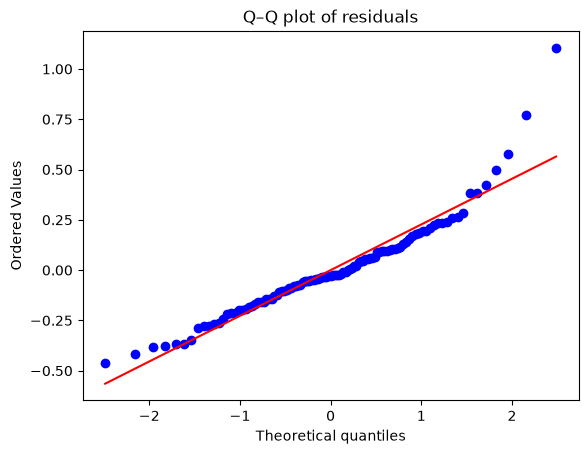

Test statistic: 40.942
P-value: 1.287e-09


In [3]:
from scipy import stats

stats.probplot(residuals, dist="norm", plot=plt)
plt.title("Q–Q plot of residuals")
plt.show()

statistic, p_value = stats.normaltest(residuals)
print(f"Test statistic: {statistic:.3f}")
print(f"P-value: {p_value:.4g}")

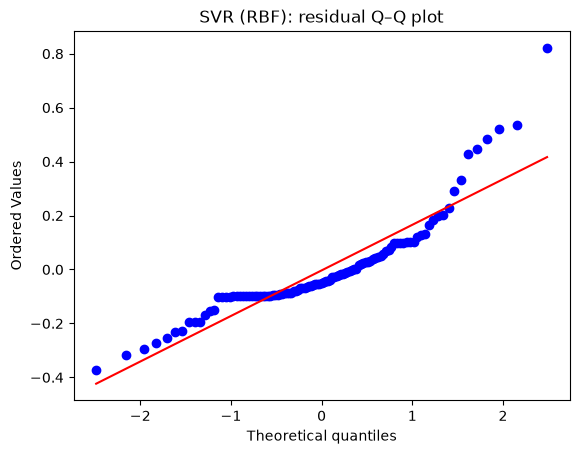

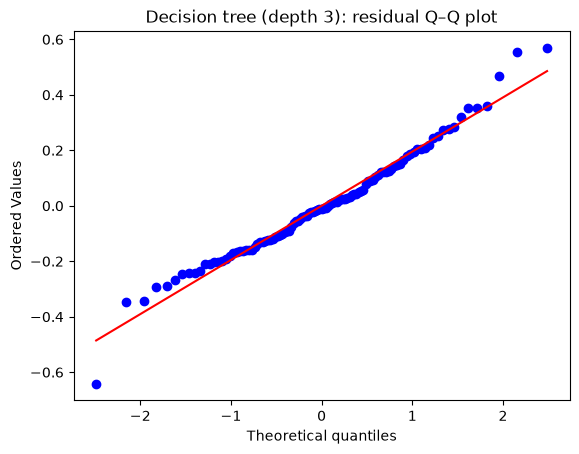

,Model,Statistic,P-value
0,Linear regression,40.942406,1.286677e-09
1,SVR (RBF),48.972624,2.321293e-11
2,Decision tree (depth 3),5.030581,8.083943e-02


In [4]:
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.preprocessing import StandardScaler

q4_results = [{"Model": "Linear regression", "Statistic": float(statistic), "P-value": float(p_value)}]
q4_models = {
    "SVR (RBF)": make_pipeline(StandardScaler(), SVR()),
    "Decision tree (depth 3)": DecisionTreeRegressor(max_depth=3, random_state=42)
}

for name, fitted_model in q4_models.items():
    fitted_model.fit(X, y)
    model_residuals = y - fitted_model.predict(X)
    test_statistic, test_p_value = stats.normaltest(model_residuals)
    q4_results.append({"Model": name, "Statistic": float(test_statistic), "P-value": float(test_p_value)})
    plt.figure()
    stats.probplot(model_residuals, dist="norm", plot=plt)
    plt.title(f"{name}: residual Q–Q plot")
    plt.show()

pd.DataFrame(q4_results)

# Q5 - Classification

In [5]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

cancer = load_breast_cancer()

X_cancer = cancer.data
y_cancer = cancer.target

X_train, X_test, y_train, y_test = train_test_split(
    X_cancer,
    y_cancer,
    test_size=0.2,
    random_state=42,
    stratify=y_cancer
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

baseline = LogisticRegression(max_iter=1000)
baseline.fit(X_train_scaled, y_train)

baseline_predictions = baseline.predict(X_test_scaled)
baseline_accuracy = accuracy_score(y_test, baseline_predictions)

print(f"Baseline test accuracy: {baseline_accuracy:.2%}")

Baseline test accuracy: 98.25%


## Part a

In [6]:
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(42)

X_train_t = torch.tensor(X_train_scaled, dtype=torch.float32)
X_test_t = torch.tensor(X_test_scaled, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.float32).reshape(-1, 1)

logistic_model = nn.Sequential(
    nn.Linear(X_train_t.shape[1], 1),
    nn.Sigmoid()
)

def binary_cross_entropy(probabilities, targets):

    p = probabilities.clamp(min=1e-7, max=1 - 1e-7)
    losses = -(
        targets * torch.log(p)
        + (1 - targets) * torch.log(1 - p)
    )
    return losses.mean()

optimizer = torch.optim.SGD(logistic_model.parameters(), lr=0.01)

train_loader = DataLoader(
    TensorDataset(X_train_t, y_train_t),
    batch_size=32,
    shuffle=True
)

for epoch in range(200):
    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()
        probabilities = logistic_model(X_batch)
        loss = binary_cross_entropy(probabilities, y_batch)
        loss.backward()
        optimizer.step()

with torch.no_grad():
    test_probabilities = logistic_model(X_test_t)
    custom_predictions = (test_probabilities >= 0.5).int().numpy().ravel()

custom_accuracy = accuracy_score(y_test, custom_predictions)

print(f"Custom logistic test accuracy: {custom_accuracy:.2%}")
print(f"Scikit-learn baseline accuracy: {baseline_accuracy:.2%}")

Custom logistic test accuracy: 97.37%
Scikit-learn baseline accuracy: 98.25%


## Part b

In [7]:
torch.manual_seed(42)
probit_model = nn.Linear(X_train_t.shape[1], 1)
standard_normal = torch.distributions.Normal(0.0, 1.0)
probit_optimizer = torch.optim.SGD(probit_model.parameters(), lr=0.01)
probit_loader = DataLoader(
    TensorDataset(X_train_t, y_train_t), batch_size=32, shuffle=True
)

for epoch in range(200):
    for X_batch, y_batch in probit_loader:
        probit_optimizer.zero_grad()

        probabilities = standard_normal.cdf(probit_model(X_batch))
        loss = binary_cross_entropy(probabilities, y_batch)
        loss.backward()
        probit_optimizer.step()

with torch.no_grad():
    probit_probabilities = standard_normal.cdf(probit_model(X_test_t))
    probit_predictions = (probit_probabilities >= 0.5).int().numpy().ravel()

probit_accuracy = accuracy_score(y_test, probit_predictions)
print(f"Probit test accuracy: {probit_accuracy:.2%}")
print(f"Custom logistic test accuracy: {custom_accuracy:.2%}")
print(f"Scikit-learn baseline accuracy: {baseline_accuracy:.2%}")

Probit test accuracy: 97.37%
Custom logistic test accuracy: 97.37%
Scikit-learn baseline accuracy: 98.25%


# Q5 - Regression

In [8]:
from sklearn.metrics import mean_absolute_error

X_ale = df[["anchor_ratio", "trans_range", "node_density", "iterations"]]
y_ale = df["ale"]
X_ale_train, X_ale_test, y_ale_train, y_ale_test = train_test_split(
    X_ale, y_ale, test_size=0.2, random_state=42
)

ale_scaler = StandardScaler()
X_ale_train_scaled = ale_scaler.fit_transform(X_ale_train)
X_ale_test_scaled = ale_scaler.transform(X_ale_test)

ale_baseline = LinearRegression()
ale_baseline.fit(X_ale_train_scaled, y_ale_train)
ale_baseline_predictions = ale_baseline.predict(X_ale_test_scaled)
ale_baseline_mae = mean_absolute_error(y_ale_test, ale_baseline_predictions)

print(f"Scikit-learn linear regression test MAE: {ale_baseline_mae:.4f}")

Scikit-learn linear regression test MAE: 0.1954


## Part a

In [9]:
X_ale_train_t = torch.tensor(X_ale_train_scaled, dtype=torch.float32)
X_ale_test_t = torch.tensor(X_ale_test_scaled, dtype=torch.float32)
y_ale_train_t = torch.tensor(
    y_ale_train.to_numpy(), dtype=torch.float32
).reshape(-1, 1)

torch.manual_seed(42)
mse_model = nn.Linear(X_ale_train_t.shape[1], 1)
mse_optimizer = torch.optim.SGD(mse_model.parameters(), lr=0.01)
mse_loader = DataLoader(
    TensorDataset(X_ale_train_t, y_ale_train_t), batch_size=16, shuffle=True
)

def mean_squared_error_loss(predictions, targets):
    return ((targets - predictions) ** 2).mean()

for epoch in range(500):
    for X_batch, y_batch in mse_loader:
        mse_optimizer.zero_grad()
        predictions_batch = mse_model(X_batch)
        loss = mean_squared_error_loss(predictions_batch, y_batch)
        loss.backward()
        mse_optimizer.step()

with torch.no_grad():
    mse_predictions = mse_model(X_ale_test_t).numpy().ravel()

mse_mae = mean_absolute_error(y_ale_test, mse_predictions)
print(f"Scikit-learn linear regression test MAE: {ale_baseline_mae:.4f}")
print(f"Custom linear regression (MSE) test MAE: {mse_mae:.4f}")

Scikit-learn linear regression test MAE: 0.1954
Custom linear regression (MSE) test MAE: 0.1952


## Part b

In [10]:
torch.manual_seed(42)
student_t_model = nn.Linear(X_ale_train_t.shape[1], 1)
student_t_optimizer = torch.optim.SGD(student_t_model.parameters(), lr=0.01)
student_t_loader = DataLoader(
    TensorDataset(X_ale_train_t, y_ale_train_t), batch_size=16, shuffle=True
)

student_t_distribution = torch.distributions.StudentT(
    df=5.0, loc=0.0, scale=1.0
)

def student_t_loss(predictions, targets):
    residuals_batch = targets - predictions
    return -student_t_distribution.log_prob(residuals_batch).mean()

for epoch in range(500):
    for X_batch, y_batch in student_t_loader:
        student_t_optimizer.zero_grad()
        predictions_batch = student_t_model(X_batch)
        loss = student_t_loss(predictions_batch, y_batch)
        loss.backward()
        student_t_optimizer.step()

with torch.no_grad():
    student_t_predictions = student_t_model(X_ale_test_t).numpy().ravel()

student_t_mae = mean_absolute_error(y_ale_test, student_t_predictions)
print(f"Student-t loss (nu=5) test MAE: {student_t_mae:.4f}")
print(f"MSE loss test MAE: {mse_mae:.4f}")
print(f"Scikit-learn baseline test MAE: {ale_baseline_mae:.4f}")

Student-t loss (nu=5) test MAE: 0.1941
MSE loss test MAE: 0.1952
Scikit-learn baseline test MAE: 0.1954
